# クラスの偏ったデータを扱う（クラス重み・しきい値調整）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/12_classification/imbalanced.ipynb)

NLP クックブック 12-09 ／ テキスト分類

陽性が数 % しかないデータ（スパム、有害投稿、異常報告など）で、少数クラスをきちんと検出したい。

In [1]:
from sklearn.base import clone
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, classification_report, precision_recall_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline

data = fetch_20newsgroups(subset="all", remove=("headers", "footers", "quotes"))
y = (data.target == data.target_names.index("sci.med")).astype(int)   # 「医療」だけを陽性（約 5%）とする 2 値分類
X_train, X_test, y_train, y_test = train_test_split(data.data, y, test_size=0.3, stratify=y, random_state=0)
pipe = Pipeline([
    ("tfidf", TfidfVectorizer(stop_words="english", sublinear_tf=True, min_df=2)),
    ("clf", LogisticRegression(C=1, max_iter=1000)),
])
print(f"陽性の割合: {y.mean():.1%}")

for cw in [None, "balanced"]:
    clf = clone(pipe).set_params(clf__class_weight=cw).fit(X_train, y_train)
    print(f"\nclass_weight={cw}")
    print(classification_report(y_test, clf.predict(X_test), digits=3, target_names=["other", "med"]))

陽性の割合: 5.3%

class_weight=None
              precision    recall  f1-score   support

       other      0.960     1.000     0.979      5357
         med      1.000     0.239     0.386       297

    accuracy                          0.960      5654
   macro avg      0.980     0.620     0.683      5654
weighted avg      0.962     0.960     0.948      5654


class_weight=balanced
              precision    recall  f1-score   support

       other      0.990     0.993     0.991      5357
         med      0.864     0.811     0.837       297

    accuracy                          0.983      5654
   macro avg      0.927     0.902     0.914      5654
weighted avg      0.983     0.983     0.983      5654



交差検証で選んだしきい値: 0.11
平均適合率 (AP) = 0.885
しきい値 0.50 → 適合率 1.000 / 再現率 0.239 / F1 0.386
しきい値 0.11 → 適合率 0.861 / 再現率 0.811 / F1 0.835


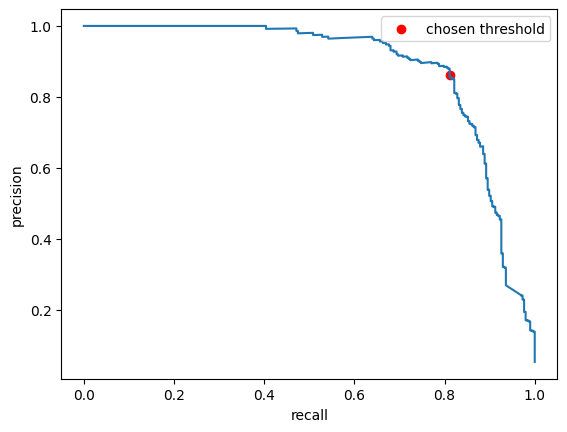

In [2]:
# しきい値を動かして適合率と再現率のバランスを選ぶ
import matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score
from sklearn.model_selection import cross_val_predict

# TF-IDF と分類器を各分割の学習側で学習し、検証側の予測確率を集める
prob_cv = cross_val_predict(pipe, X_train, y_train, cv=5, method="predict_proba")[:, 1]
precision, recall, thresholds = precision_recall_curve(y_train, prob_cv)
f1 = 2 * precision * recall / (precision + recall + 1e-9)
best_th = thresholds[f1[:-1].argmax()]
print(f"交差検証で選んだしきい値: {best_th:.2f}")

# 決めたしきい値を、テストデータで測る
pipe.fit(X_train, y_train)
prob = pipe.predict_proba(X_test)[:, 1]
print(f"平均適合率 (AP) = {average_precision_score(y_test, prob):.3f}")
for th in [0.5, best_th]:
    pred = prob >= th
    print(f"しきい値 {th:.2f} → 適合率 {precision_score(y_test, pred):.3f} / 再現率 {recall_score(y_test, pred):.3f} / F1 {f1_score(y_test, pred):.3f}")

precision, recall, _ = precision_recall_curve(y_test, prob)
plt.plot(recall, precision)
plt.scatter(recall_score(y_test, prob >= best_th), precision_score(y_test, prob >= best_th), color="red", label="chosen threshold")
plt.xlabel("recall"); plt.ylabel("precision"); plt.legend(); plt.show()

- 不均衡データでは、全部「陰性」と答えても正解率が約 95% になる。少数クラスの適合率・再現率・F1 や平均適合率 (AP) を見る。
- `class_weight="balanced"` は少数クラスの誤りを重く扱う。再現率が上がり、適合率は下がる。
- `Pipeline` に TF-IDF と分類器をまとめ、生の文書を交差検証に渡すと、語彙と IDF は各分割の学習側だけで決まる。検証側の予測確率でしきい値を選び、テストデータで評価する。「見逃しを減らしたい」のか「誤検出を減らしたい」のか、用途に応じて選ぶ。